In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from pandas.plotting import scatter_matrix
from sklearn import preprocessing  
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn import svm
from xgboost import XGBClassifier
from sklearn import metrics

In [2]:
dataframe = pd.read_csv('diabetes.csv')

In [3]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               392 non-null    int64  
 1   Glucose                   392 non-null    int64  
 2   BloodPressure             392 non-null    int64  
 3   SkinThickness             392 non-null    int64  
 4   Insulin                   392 non-null    int64  
 5   BMI                       392 non-null    float64
 6   DiabetesPedigreeFunction  392 non-null    float64
 7   Age                       392 non-null    int64  
 8   Outcome                   392 non-null    str    
dtypes: float64(2), int64(6), str(1)
memory usage: 27.7 KB


In [4]:
dataframe.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,1,89,66,23,94,28.1,0.167,21,N
1,0,137,40,35,168,43.1,2.288,33,Y
2,3,78,50,32,88,31.0,0.248,26,Y
3,2,197,70,45,543,30.5,0.158,53,Y
4,1,189,60,23,846,30.1,0.398,59,Y


In [5]:
dataframe.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
387,0,181,88,44,510,43.3,0.222,26,Y
388,1,128,88,39,110,36.5,1.057,37,Y
389,2,88,58,26,16,28.4,0.766,22,N
390,10,101,76,48,180,32.9,0.171,63,N
391,5,121,72,23,112,26.2,0.245,30,N


In [6]:
dataframe.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,3.301020,122.627551,70.663265,29.145408,156.056122,33.086224,0.523046,30.864796
std,3.211424,30.860781,12.496092,10.516424,118.841690,7.027659,0.345488,10.200777
min,0.000000,56.000000,24.000000,7.000000,14.000000,18.200000,0.085000,21.000000
25%,1.000000,99.000000,62.000000,21.000000,76.750000,28.400000,0.269750,23.000000
50%,2.000000,119.000000,70.000000,29.000000,125.500000,33.200000,0.449500,27.000000
75%,5.000000,143.000000,78.000000,37.000000,190.000000,37.100000,0.687000,36.000000
max,17.000000,198.000000,110.000000,63.000000,846.000000,67.100000,2.420000,81.000000


In [7]:
dataframe.loc[0 , 'Glucose']

np.int64(89)

In [8]:
dataframe.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [9]:
label_encoder = preprocessing.LabelEncoder()
str = (dataframe.dtypes == 'str')
str_cols = list(str[str].index)

for col in str_cols :
    dataframe[col] = label_encoder.fit_transform(dataframe[col])

In [10]:
features_names = dataframe.drop('Outcome' , axis=1)
target = dataframe['Outcome']

<Axes: xlabel='Outcome', ylabel='count'>

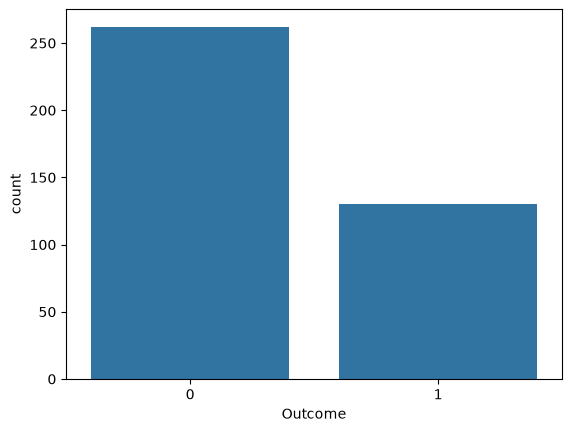

In [11]:
sns.countplot(x='Outcome' , data=dataframe)

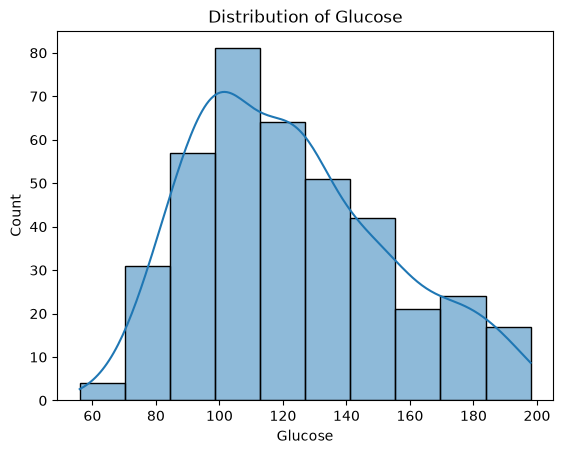

In [12]:
sns.histplot(data=dataframe , x='Glucose' , bins=10 , kde=True)

plt.title('Distribution of Glucose')
plt.xlabel('Glucose')
plt.ylabel('Count')
plt.show()

In [13]:
dataframe.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,3.301020,122.627551,70.663265,29.145408,156.056122,33.086224,0.523046,30.864796,0.331633
std,3.211424,30.860781,12.496092,10.516424,118.841690,7.027659,0.345488,10.200777,0.471401
min,0.000000,56.000000,24.000000,7.000000,14.000000,18.200000,0.085000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,21.000000,76.750000,28.400000,0.269750,23.000000,0.000000
50%,2.000000,119.000000,70.000000,29.000000,125.500000,33.200000,0.449500,27.000000,0.000000
75%,5.000000,143.000000,78.000000,37.000000,190.000000,37.100000,0.687000,36.000000,1.000000
max,17.000000,198.000000,110.000000,63.000000,846.000000,67.100000,2.420000,81.000000,1.000000


<Axes: >

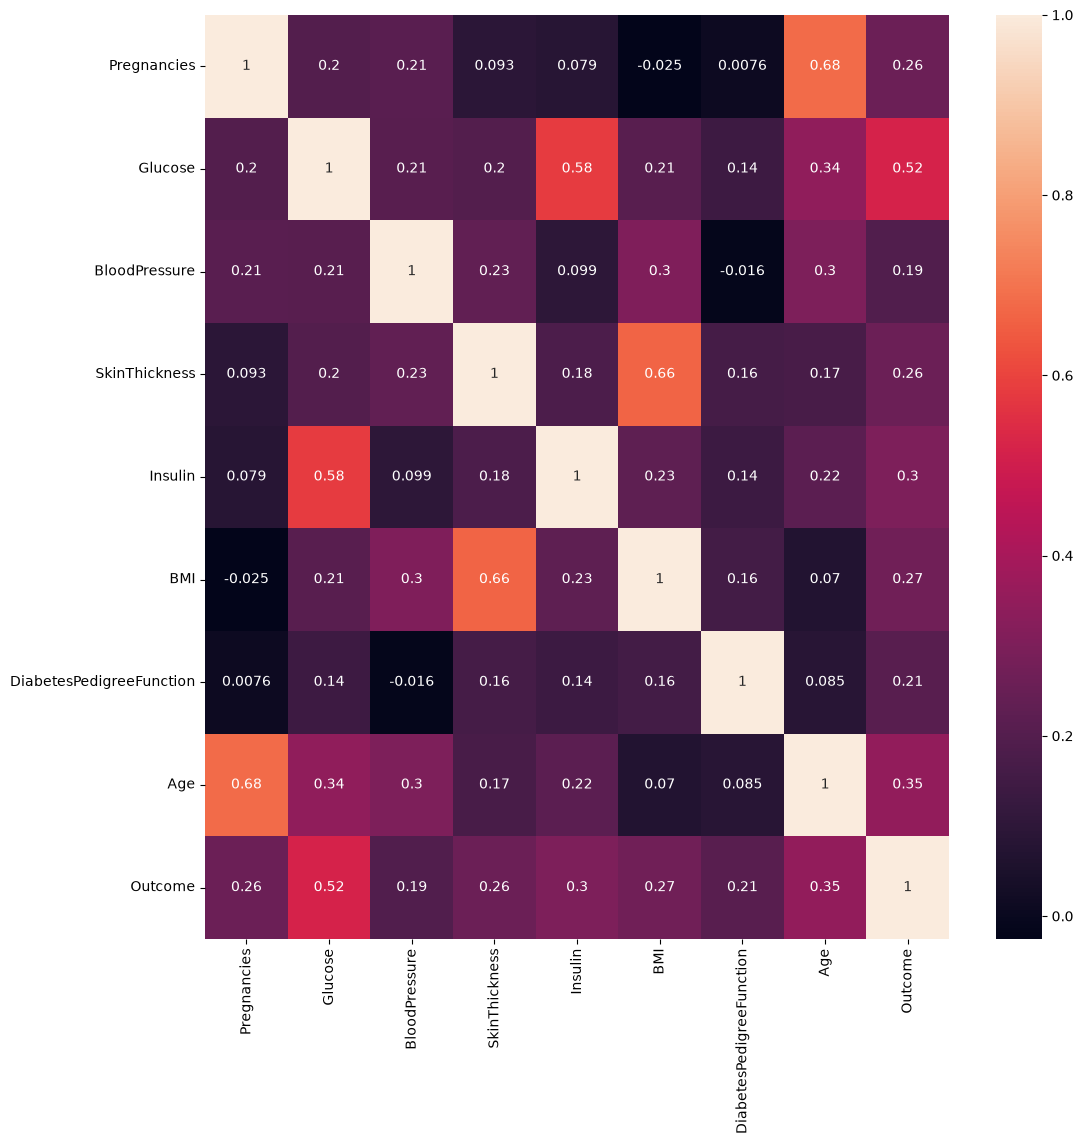

In [14]:
plt.subplots(figsize=(12,12))
sns.heatmap(dataframe.corr() , annot=True)

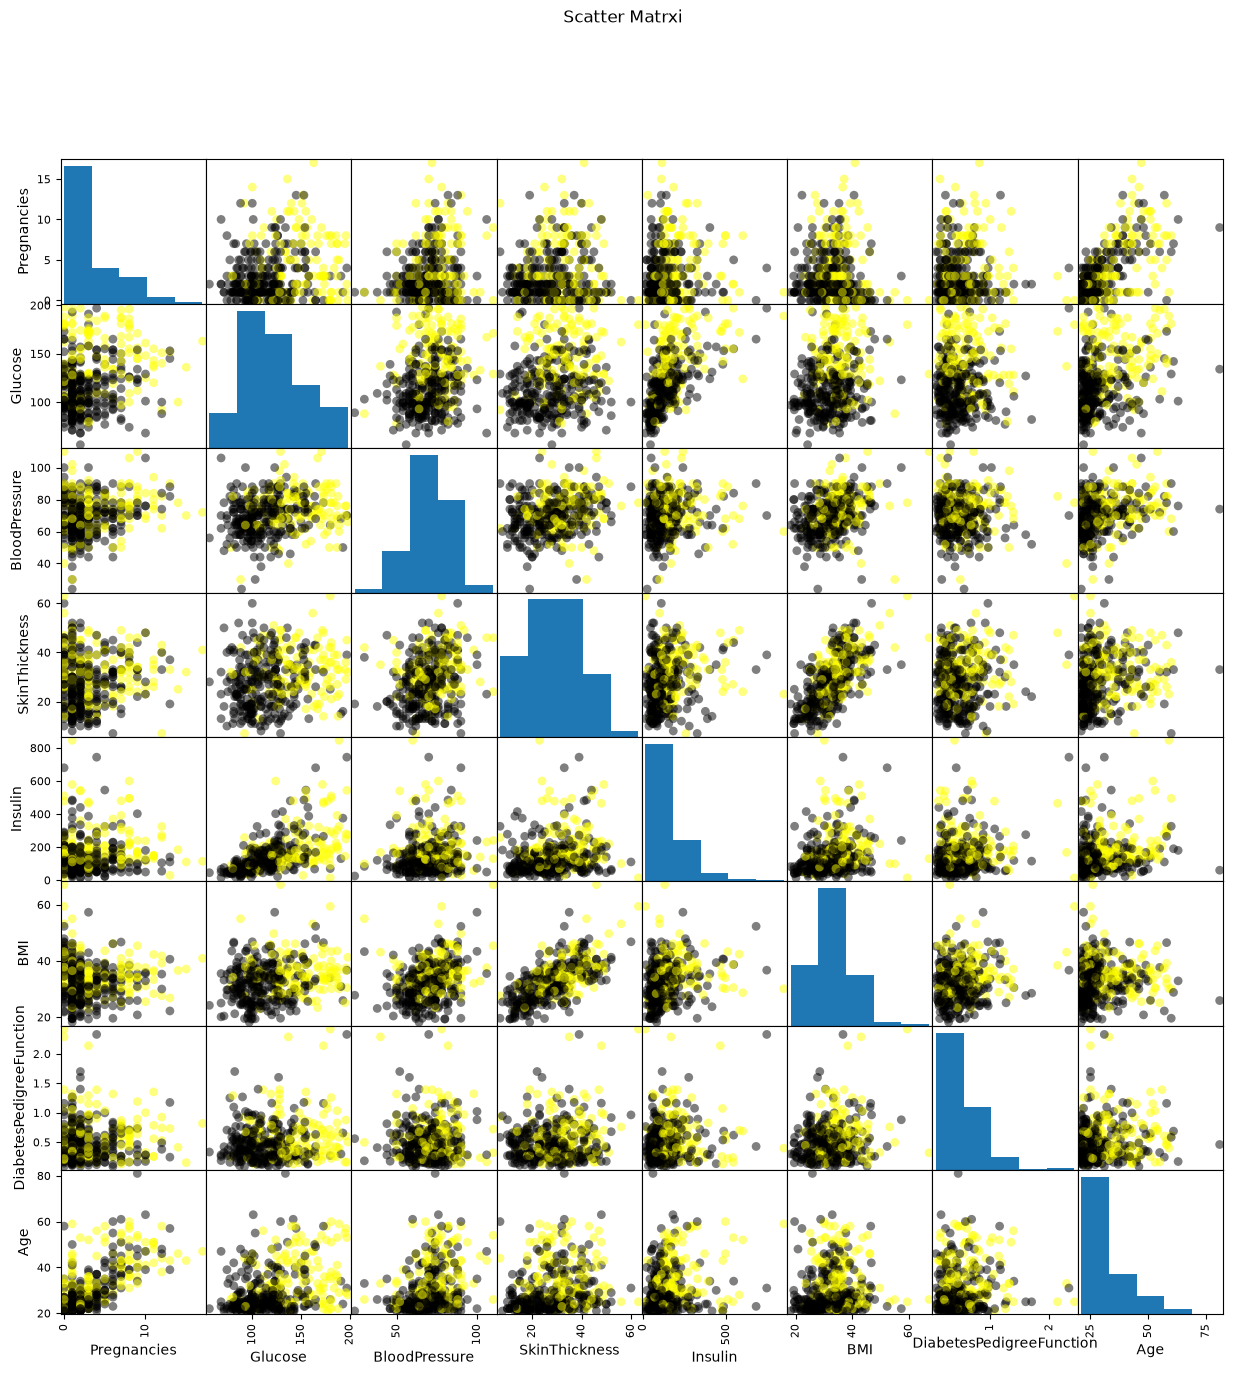

In [15]:
scatter_matrix = scatter_matrix(features_names , c = target , marker='o' , s = 40 , hist_kwds={'bins':5} , figsize=(15 , 15) , cmap='gnuplot')

plt.suptitle('Scatter Matrxi')
plt.savefig('scatter_matrix.jpg')

In [16]:
for col in dataframe.columns : 
    dataframe[col] = dataframe[col].fillna(dataframe[col].mean())

dataframe.isna().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [17]:
X_train , X_test , Y_train , Y_test  = train_test_split(features_names , target , test_size = 0.2 , random_state=42)

In [18]:
scaler = preprocessing.MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [19]:
X_train

array([[0.        , 0.87323944, 0.76744186, ..., 0.35983264, 0.09807281,
        0.23333333],
       [0.2       , 0.17605634, 0.72093023, ..., 0.17154812, 0.09464668,
        0.01666667],
       [0.53333333, 0.49295775, 0.74418605, ..., 0.40167364, 0.1130621 ,
        0.46666667],
       ...,
       [0.        , 0.42957746, 0.48837209, ..., 0.24058577, 0.17473233,
        0.01666667],
       [0.2       , 0.47183099, 0.88372093, ..., 0.79497908, 0.34047109,
        0.01666667],
       [0.6       , 0.3943662 , 0.6744186 , ..., 0.31171548, 0.07494647,
        0.25      ]], shape=(313, 8))

In [21]:
models = {
    'LogisticRegression':LogisticRegression(max_iter=1000 , C=1.0),
    'KNN':KNeighborsClassifier(n_neighbors=5 , weights='uniform'),
    'RandomForestClassifier':RandomForestClassifier(n_estimators=100 , max_depth=5),
    'DecisionTreeClassifier':DecisionTreeClassifier(criterion='gini' , max_depth=5),
    'XGBoost':XGBClassifier(n_estimators=100 , learning_rate=0.1),
    'GradientBoostingClassifier':GradientBoostingClassifier(n_estimators=100 , learning_rate=0.1),
    'Naive Bayes':GaussianNB(var_smoothing=1e-9),
    'SVM':svm.SVC(kernel='linear' , C=1.0)
}

for name , model in models.items():
    model.fit(X_train , Y_train)
    y_pred = model.predict(X_test)

    accuracy_score = metrics.accuracy_score(Y_test , y_pred)

    person =  np.array([[1, 115, 70, 30, 96, 34.6, 0.529, 32]])
    prediction = model.predict(person)

    print(name)
    print('Score:',accuracy_score)
    print(prediction)
    print('------------')

LogisticRegression
Score: 0.7721518987341772
[1]
------------
KNN
Score: 0.7468354430379747
[1]
------------
RandomForestClassifier
Score: 0.759493670886076
[1]
------------
DecisionTreeClassifier
Score: 0.759493670886076
[1]
------------
XGBoost
Score: 0.7215189873417721
[1]
------------
GradientBoostingClassifier
Score: 0.7468354430379747
[0]
------------
Naive Bayes
Score: 0.7468354430379747
[1]
------------
SVM
Score: 0.759493670886076
[1]
------------


In [22]:
model = GaussianNB()

model.fit(X_train , Y_train)
y_pred = model.predict(X_test)

accuracy_score = metrics.accuracy_score(Y_test , y_pred)


person =  np.array([[1, 115, 70, 30, 96, 34.6, 0.529, 32]])
prediction = model.predict(person)

print('Score:',accuracy_score)
print(prediction)

Score: 0.7468354430379747
[1]
